In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [4]:
base = ['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']
df = df[base]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


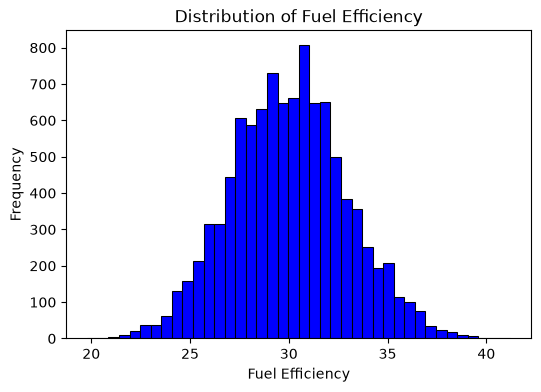

In [5]:
plt.figure(figsize=(6, 4))

sns.histplot(df.fuel_efficiency_mpg, bins=40, color='blue', alpha=1)
plt.ylabel('Frequency')
plt.xlabel('Fuel Efficiency')
plt.title('Distribution of Fuel Efficiency')

plt.show()

In [6]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [7]:
md_hp = df['horsepower'].median()
print(md_hp)

254.0


In [8]:
#Preparing the data
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

y_train_orig = df_train.fuel_efficiency_mpg.values
y_val_orig = df_val.fuel_efficiency_mpg.values
y_test_orig = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [9]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [10]:
#Model: Filling NaNs with 0
X_train = df_train.fillna(0).values
X_val = df_val.fillna(0).values
w_0, w = train_linear_regression(X_train, y_train_orig)
y_val = w_0 + X_val.dot(w)
RMSE = np.sqrt(((y_val_orig - y_val)**2).mean())
print(RMSE)

2.20529319475341


In [11]:
#Model: Filling NaNs with mean horsepower
X_train = df_train.fillna(df_train['horsepower'].mean()).values
X_val = df_val.fillna(df_train['horsepower'].mean()).values
w_0, w = train_linear_regression(X_train, y_train_orig)
y_val = w_0 + X_val.dot(w)
RMSE = np.sqrt(((y_val_orig - y_val)**2).mean())
print(RMSE)

2.2018174845688243


In [12]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [13]:
#Q4
X_train = df_train.fillna(0).values
X_val = df_val.fillna(0).values
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train, y_train_orig,r)
    y_val = w_0 + X_val.dot(w)
    RMSE = np.sqrt(((y_val_orig - y_val)**2).mean())
    print(r, RMSE)

0 2.20529319475341
0.01 2.2058276166720066
0.1 2.2241432777850454
1 2.3492288883928363
5 2.40938016659955
10 2.419469865473249
100 2.429202138016282


In [14]:
#Q5
RMSE = []
for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    
    y_train_orig = df_train.fuel_efficiency_mpg.values
    y_val_orig = df_val.fuel_efficiency_mpg.values
    y_test_orig = df_test.fuel_efficiency_mpg.values
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']
    
    X_train = df_train.fillna(0).values
    X_val = df_val.fillna(0).values
    w_0, w = train_linear_regression(X_train, y_train_orig)
    y_val = w_0 + X_val.dot(w)
    RMSE.append(np.sqrt(((y_val_orig - y_val)**2).mean()))


print(round(np.std(RMSE), 3))

0.029


In [21]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)
    
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)
    
y_full_train_orig = np.concatenate([y_train_orig, y_val_orig])
        
X_full_train = df_full_train.fillna(0).values
X_test = df_test.fillna(0).values
w_0, w = train_linear_regression_reg(X_full_train, y_full_train_orig, r=0.001)
y_test = w_0 + X_test.dot(w)
RMSE = np.sqrt(((y_test_orig - y_test)**2).mean())
print(RMSE)

2.235827747191731
